# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib scipy
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
kernel: d:\Repo Aprendizaje Automatico\AprendizajeAutomatico\.venv\Scripts\python.exe


In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.14.1+cpu | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [3]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 1
Estado siguiente: [ 0.004  1.425  0.22   0.295 -0.003 -0.004  0.     0.   ]
Recompensa: 2.080
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [4]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [5]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [6]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.47
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [7]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [8]:
# Implementación del agente DQN
class AgenteDQN(Agente):
    """
    Agente DQN (Deep Q-Network).
    Implementa aproximación de función con redes neuronales,
    Experience Replay y Target Network desacoplada.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 gamma=0.99, lr=5e-4, batch_size=64, buffer_size=100_000,
                 tau=1e-3, epsilon_start=1.0, epsilon_min=0.01, epsilon_decay=0.995,
                 # Arquitectura de la red: un ancho por capa oculta
                 capas_ocultas=(64, 64),
                 # Interruptores para el estudio de ablación (sección 11)
                 usar_target_net=True, usar_replay_buffer=True, usar_huber=True):
        
        # -------------------------------------------------------------
        # 1. SEMILLAS ALEATORIAS (Reproducibilidad)
        # -------------------------------------------------------------
        # Fijamos la semilla en todos los generadores involucrados:
        # random (Python puro), numpy, torch y el espacio de acciones de Gymnasium.
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)

        self.accion_space = accion_space
        # LunarLander tiene 8 dimensiones en observación y 4 acciones discretas
        self.num_estados = estado_space.shape[0]   # 8
        self.num_acciones = accion_space.n        # 4
        
        # -------------------------------------------------------------
        # 2. HIPERPARÁMETROS
        # -------------------------------------------------------------
        self.gamma = gamma                    # Factor de descuento de Bellman
        self.batch_size = batch_size          # Tamaño del lote para optimizar
        self.tau = tau                        # Tasa para el Soft Update (mezcla suave)
        self.epsilon = epsilon_start          # Probabilidad inicial de exploración
        self.epsilon_min = epsilon_min        # Cota inferior de exploración
        self.epsilon_decay = epsilon_decay    # Factor de decaimiento por episodio
        
        # Ablación: con False, el componente correspondiente se desactiva
        self.usar_target_net = usar_target_net          # False: el objetivo usa red_q
        self.usar_replay_buffer = usar_replay_buffer    # False: aprende solo de la última transición
        self.funcion_perdida = F.smooth_l1_loss if usar_huber else F.mse_loss

        # -------------------------------------------------------------
        # 3. REDES NEURONALES (PyTorch)
        # -------------------------------------------------------------
        # Perceptrón Multicapa (MLP) con ReLU: por defecto [8 -> 64 -> 64 -> 4]
        def construir_red():
            capas, entrada = [], self.num_estados
            for ancho in capas_ocultas:
                capas += [nn.Linear(entrada, ancho), nn.ReLU()]
                entrada = ancho
            return nn.Sequential(*capas, nn.Linear(entrada, self.num_acciones))

        # Red Principal (Policy Network): se optimiza activamente con gradiente descendente
        self.red_q = construir_red()
        
        # Red Objetivo (Target Network): red desacoplada para estabilizar el cálculo de Bellman
        self.red_target = construir_red()
        self.red_target.load_state_dict(self.red_q.state_dict())
        self.red_target.eval()

        # Optimizador Adam: se encarga de aplicar los gradientes sobre los pesos de red_q
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

        # -------------------------------------------------------------
        # 4. EXPERIENCE REPLAY BUFFER
        # -------------------------------------------------------------
        # Cola de memoria circular con capacidad máxima fija
        self.memoria = deque(maxlen=buffer_size)

    # =================================================================
    # POLÍTICA DE SELECCIÓN DE ACCIÓN (Epsilon-Greedy)
    # =================================================================
    def elegir_accion(self, estado, explorar=True):
        """
        Dada una observación del entorno, decide qué acción tomar (0, 1, 2 o 3).
        Con explorar=True aplica la política epsilon-greedy.
        Con explorar=False (evaluación), elige la mejor acción determinista (greedy).
        """
        # Exploración: acción aleatoria uniforme
        if explorar and random.random() < self.epsilon:
            return self.accion_space.sample()
        
        # Explotación: consultamos la red neuronal (greedy)
        # 1) Convertimos el array de NumPy a tensor de PyTorch.
        # 2) .unsqueeze(0) agrega la dimensión del lote: pasa de tamaño (8,) a (1, 8).
        estado_t = torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)
        
        # torch.no_grad() desactiva el cálculo de gradientes durante la inferencia
        with torch.no_grad():
            q_valores = self.red_q(estado_t)  # Salida: tensor (1, 4)
            
        # .argmax(dim=1) devuelve el índice con el mayor valor Q, y .item() lo convierte a int
        return int(q_valores.argmax(dim=1).item())

    # =================================================================
    # APRENDIZAJE Y GUARDADO DE EXPERIENCIAS
    # =================================================================
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """
        Almacena la transición en el buffer y ejecuta un paso de optimización
        cuando hay suficientes experiencias acumuladas.
        """
        # 1. Guardar la transición (s, a, r, s', terminado) en el Replay Buffer
        self.memoria.append((estado, accion, recompensa, siguiente_estado, terminado))
        
        # 2. Entrenar la red solo si acumulamos al menos un lote completo
        # (sin Replay Buffer se aprende de inmediato, de la transición recién vista)
        if not self.usar_replay_buffer or len(self.memoria) >= self.batch_size:
            self._optimizar_red()

    def fin_episodio(self):
        """
        Invocado por el bucle de entrenamiento al terminar cada episodio.
        Aplica el decaimiento de epsilon para reducir la exploración gradualmente.
        """
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    # =================================================================
    # MÉTODOS AUXILIARES INTERNOS
    # =================================================================
    def _optimizar_red(self):
        """
        Extrae un lote de experiencias del buffer, calcula la pérdida de Bellman
        y actualiza los pesos de red_q mediante backpropagation.
        """
        # 1. Muestreo de experiencias (sin Replay Buffer, solo la última transición)
        if self.usar_replay_buffer:
            lote = random.sample(self.memoria, self.batch_size)
        else:
            lote = [self.memoria[-1]]

        # zip(*lote) transpone la lista de tuplas a tuplas por componente
        estados, acciones, recompensas, sig_estados, terminados = zip(*lote)

        # 2. Conversión a Tensores de PyTorch
        estados_t = torch.as_tensor(np.array(estados), dtype=torch.float32)                   # (64, 8)
        acciones_t = torch.as_tensor(acciones, dtype=torch.int64).unsqueeze(1)               # (64, 1)
        recompensas_t = torch.as_tensor(recompensas, dtype=torch.float32).unsqueeze(1)       # (64, 1)
        sig_estados_t = torch.as_tensor(np.array(sig_estados), dtype=torch.float32)           # (64, 8)
        terminados_t = torch.as_tensor(terminados, dtype=torch.float32).unsqueeze(1)         # (64, 1)

        # 3. Predicción actual: Q(s, a; θ)
        # .gather(1, acciones_t) extrae únicamente el valor Q de la acción que efectivamente se tomó
        q_pred = self.red_q(estados_t).gather(1, acciones_t)

        # 4. Cálculo del Objetivo de Bellman: y = r + γ * max_a' Q(s', a'; θ⁻) * (1 - terminado)
        with torch.no_grad():
            red_objetivo = self.red_target if self.usar_target_net else self.red_q
            q_siguiente = red_objetivo(sig_estados_t).max(1, keepdim=True)[0]
            target_bellman = recompensas_t + (1.0 - terminados_t) * self.gamma * q_siguiente

        # 5. Cálculo de Error y Backpropagation
        # Pérdida Smooth L1 (Huber Loss): robusta ante outliers y saltos bruscos
        # (con usar_huber=False es la MSE clásica)
        perdida = self.funcion_perdida(q_pred, target_bellman)

        self.optimizador.zero_grad()  # Limpia los gradientes acumulados
        perdida.backward()            # Calcula las derivadas parciales (Autograd)
        self.optimizador.step()        # Actualiza los pesos de red_q aplicando la regla de Adam

        # 6. Actualización Suave de la Red Objetivo (Soft Update)
        # Sin target network no hay nada que actualizar
        if self.usar_target_net:
            self._actualizar_target()

    def _actualizar_target(self):
        """
        Soft update (Promedio de Polyak):
        θ_target = τ * θ_local + (1 - τ) * θ_target
        Actualiza suavemente la red objetivo mezclando una fracción tau de los pesos en cada paso.
        """
        for param_q, param_target in zip(self.red_q.parameters(), self.red_target.parameters()):
            param_target.data.copy_(self.tau * param_q.data + (1.0 - self.tau) * param_target.data)

## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [9]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA)

print("\nEntrenando el agente DQN en LunarLander-v3...")
recompensas_episodios, longitudes_episodios = entrenar_agente(
    agente_dqn, env,
    num_episodios=1200,
    max_pasos=1000,
    umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
    semilla=SEMILLA,
    verbose=True,
)

env.close()


Entrenando el agente DQN en LunarLander-v3...
Episodio    60 | Recompensa media (100 ep):  -151.66 | Longitud media:  101.6 | epsilon: 0.740 |     9s
Episodio   120 | Recompensa media (100 ep):   -97.20 | Longitud media:  131.0 | epsilon: 0.548 |    22s
Episodio   180 | Recompensa media (100 ep):   -42.24 | Longitud media:  280.7 | epsilon: 0.406 |    59s
Episodio   240 | Recompensa media (100 ep):    -6.49 | Longitud media:  472.1 | epsilon: 0.300 |   111s
Episodio   300 | Recompensa media (100 ep):    54.67 | Longitud media:  662.5 | epsilon: 0.222 |   180s
Episodio   360 | Recompensa media (100 ep):   121.44 | Longitud media:  697.6 | epsilon: 0.165 |   252s
Episodio   420 | Recompensa media (100 ep):   158.47 | Longitud media:  676.6 | epsilon: 0.122 |   323s
Episodio   480 | Recompensa media (100 ep):   198.09 | Longitud media:  646.6 | epsilon: 0.090 |   380s
Episodio   540 | Recompensa media (100 ep):   243.54 | Longitud media:  480.4 | epsilon: 0.067 |   425s
Episodio   600 | 

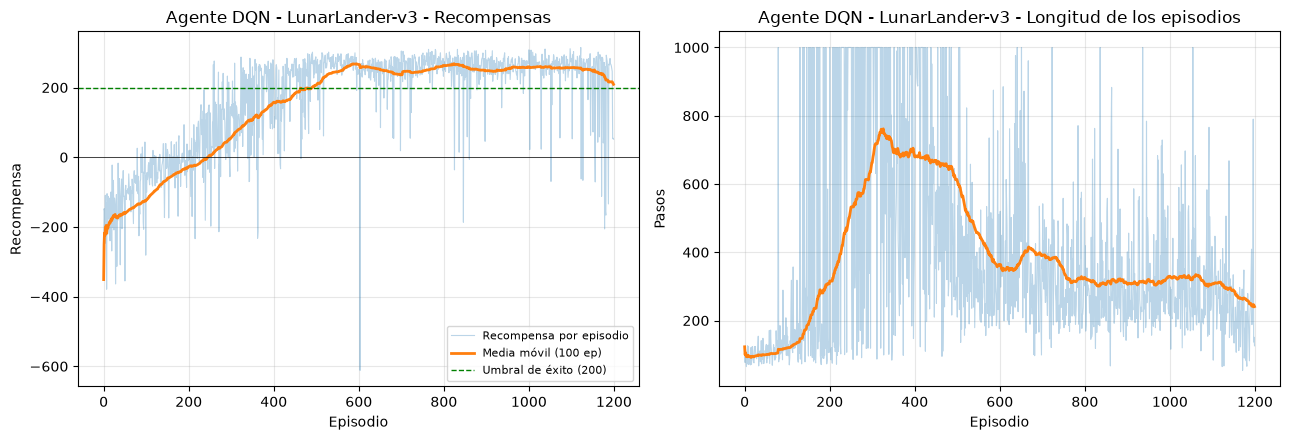

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 209.18
Tasa de éxito (R ≥ 200): 78.0%
Epsilon final: 0.010


In [10]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [11]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [12]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...

Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 77.5%
Recompensa promedio: 208.79
Recompensa mediana:  262.01
Desviación estándar: 120.25
Total de éxitos: 155 / 200

Implementación de referencia para comparar:

Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


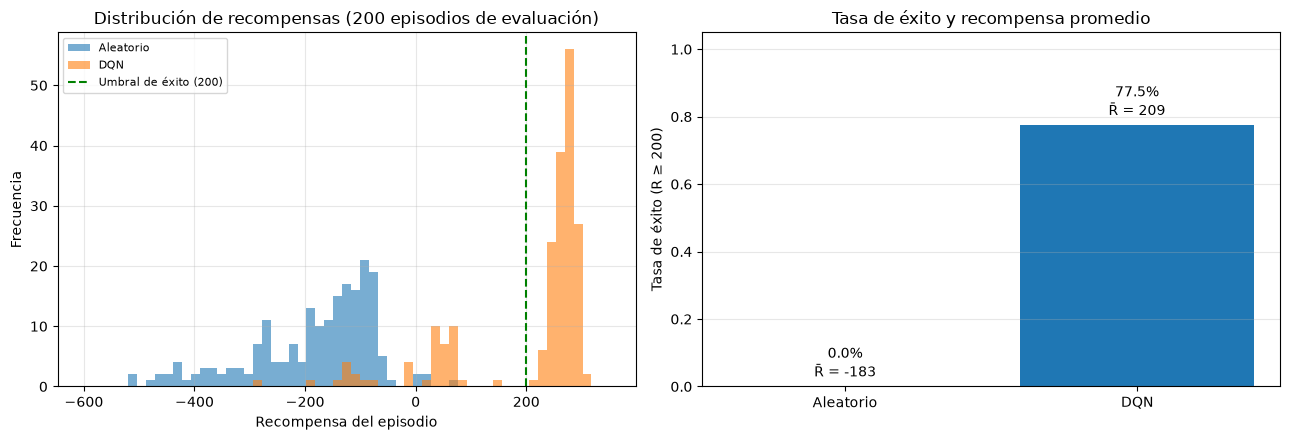

Tasa de éxito DQN:       77.5%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 392.0 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  77.5%
  R ≥  150:  78.0%
  R ≥  100:  78.0%
  R ≥    0:  92.5%
  Episodios que se estrellan (R < -50): 5.5%


In [13]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  184 pasos, recompensa   287.2
  semilla 27739:  215 pasos, recompensa   270.3
  semilla 26545:  203 pasos, recompensa   262.1
  semilla 24388:  270 pasos, recompensa   271.2
  semilla 24330:  263 pasos, recompensa   283.3
  semilla 28585:  278 pasos, recompensa   278.5
  semilla 20859:  168 pasos, recompensa   242.7
  semilla 26973:   58 pasos, recompensa   -85.4
  semilla 22014:  113 pasos, recompensa    33.3
  semilla 20941:  216 pasos, recompensa   249.1

8/10 episodios exitosos, recompensa media 209.2 → aterrizaje_dqn.gif


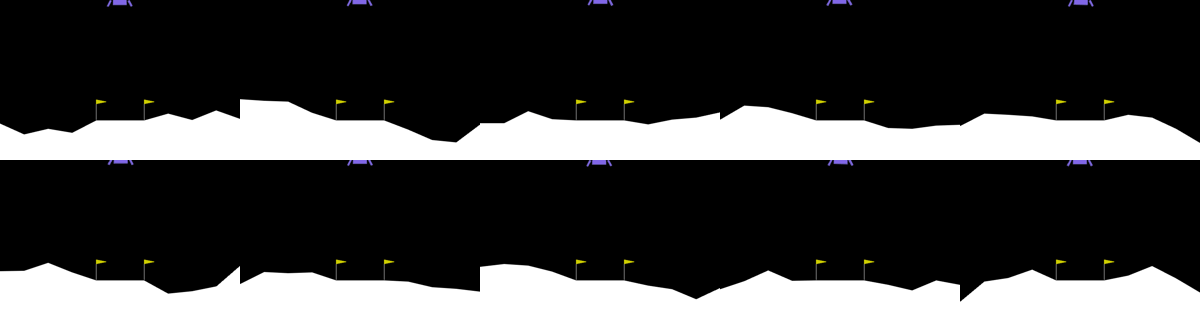

In [14]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


Control del descenso — variables fijas: x=0, vx=0, θ=0, ω=0, c_izq=0, c_der=0
Control horizontal — variables fijas: y=0.7, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0
Control de la orientación — variables fijas: x=0, y=0.7, vx=0, vy=-0.3, c_izq=0, c_der=0


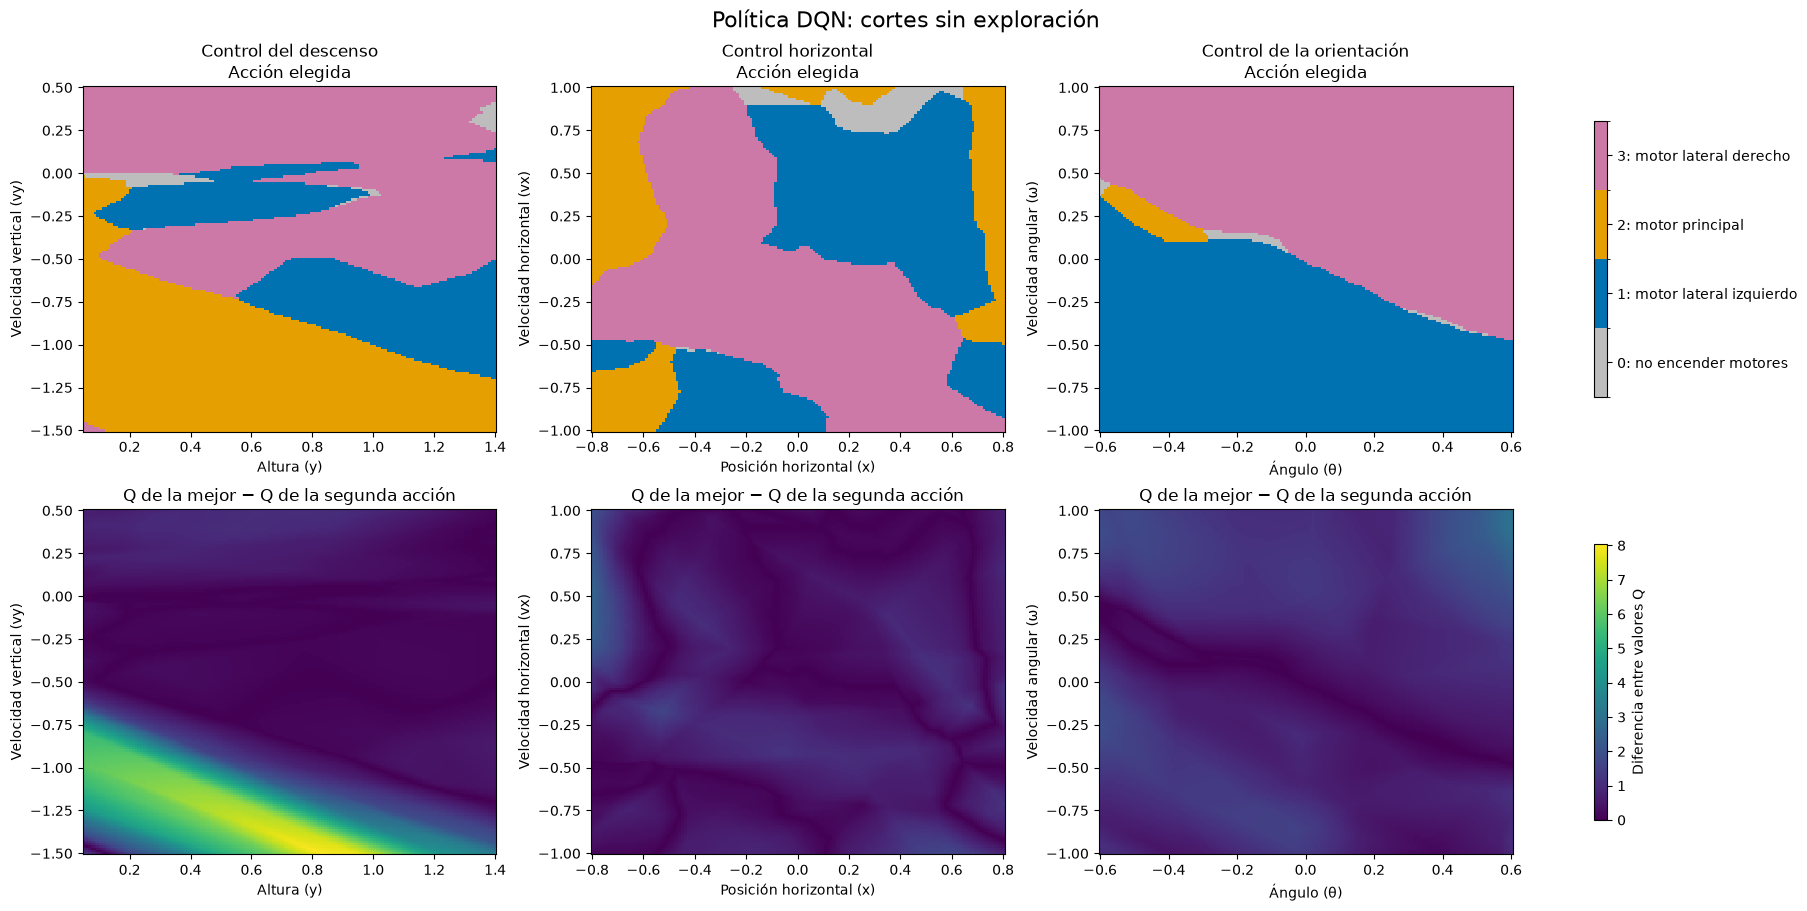

In [15]:
# Análisis de la política aprendida mediante cortes del estado.
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import ListedColormap, BoundaryNorm

# Orden de las variables:
# [x, y, vx, vy, angulo, velocidad_angular, contacto_izq, contacto_der]
nombres_estado = ["x", "y", "vx", "vy", "θ", "ω", "c_izq", "c_der"]

nombres_acciones = [
    "0: no encender motores",
    "1: motor lateral izquierdo",
    "2: motor principal",
    "3: motor lateral derecho",
]

# Cada corte modifica dos variables y mantiene las otras seis fijas.
# Los valores son coordenadas del espacio de observación de LunarLander.
cortes = [
    {
        "titulo": "Control del descenso",
        "indices": (1, 3),
        "rangos": ((0.05, 1.4), (-1.5, 0.5)),
        "etiquetas": ("Altura (y)", "Velocidad vertical (vy)"),
        "base": [0, 0.7, 0, -0.3, 0, 0, 0, 0],
    },
    {
        "titulo": "Control horizontal",
        "indices": (0, 2),
        "rangos": ((-0.8, 0.8), (-1.0, 1.0)),
        "etiquetas": ("Posición horizontal (x)", "Velocidad horizontal (vx)"),
        "base": [0, 0.7, 0, -0.3, 0, 0, 0, 0],
    },
    {
        "titulo": "Control de la orientación",
        "indices": (4, 5),
        "rangos": ((-0.6, 0.6), (-1.0, 1.0)),
        "etiquetas": ("Ángulo (θ)", "Velocidad angular (ω)"),
        "base": [0, 0.7, 0, -0.3, 0, 0, 0, 0],
    },
]

def analizar_cortes_politica(agente, cortes, resolucion=151):
    red = agente.red_q
    parametro = next(red.parameters())
    modo_previo = red.training
    resultados = []

    red.eval()
    try:
        with torch.no_grad():
            for corte in cortes:
                i, j = corte["indices"]

                eje_x = np.linspace(*corte["rangos"][0], resolucion)
                eje_y = np.linspace(*corte["rangos"][1], resolucion)
                X, Y = np.meshgrid(eje_x, eje_y)

                # Construir un estado de ocho variables por punto de la grilla.
                estados = np.tile(
                    np.asarray(corte["base"], dtype=np.float32),
                    (X.size, 1),
                )
                estados[:, i] = X.ravel()
                estados[:, j] = Y.ravel()

                estados_t = torch.as_tensor(
                    estados,
                    dtype=parametro.dtype,
                    device=parametro.device,
                )

                # Consulta directa de la red: sin exploración ni aprendizaje.
                q = red(estados_t).cpu().numpy()
                acciones = q.argmax(axis=1).reshape(X.shape)

                # Margen entre la mejor acción y la segunda mejor.
                q_ordenados = np.sort(q, axis=1)
                margen = (
                    q_ordenados[:, -1] - q_ordenados[:, -2]
                ).reshape(X.shape)

                resultados.append({
                    "corte": corte,
                    "X": X,
                    "Y": Y,
                    "acciones": acciones,
                    "margen": margen,
                    "q": q.reshape(*X.shape, q.shape[1]),
                })
    finally:
        red.train(modo_previo)

    colores = ListedColormap(["#bdbdbd", "#0072b2", "#e69f00", "#cc79a7"])
    norma_acciones = BoundaryNorm(np.arange(-0.5, 4.5, 1), colores.N)

    # Misma escala de margen para poder comparar los tres cortes.
    margen_maximo = max(float(r["margen"].max()) for r in resultados)
    margen_maximo = max(margen_maximo, 1e-8)

    fig, ejes = plt.subplots(
        2, len(resultados),
        figsize=(18, 9),
        squeeze=False,
        constrained_layout=True,
    )

    for columna, resultado in enumerate(resultados):
        corte = resultado["corte"]
        i, j = corte["indices"]

        fijos = ", ".join(
            f"{nombre}={corte['base'][k]:g}"
            for k, nombre in enumerate(nombres_estado)
            if k not in (i, j)
        )
        print(f"{corte['titulo']} — variables fijas: {fijos}")

        mapa_acciones = ejes[0, columna].pcolormesh(
            resultado["X"], resultado["Y"], resultado["acciones"],
            cmap=colores, norm=norma_acciones, shading="auto",
        )
        ejes[0, columna].set_title(
            f"{corte['titulo']}\nAcción elegida", fontsize=12
        )

        mapa_margen = ejes[1, columna].pcolormesh(
            resultado["X"], resultado["Y"], resultado["margen"],
            cmap="viridis", vmin=0, vmax=margen_maximo, shading="auto",
        )
        ejes[1, columna].set_title("Q de la mejor − Q de la segunda acción")

        for fila in range(2):
            ejes[fila, columna].set_xlabel(corte["etiquetas"][0])
            ejes[fila, columna].set_ylabel(corte["etiquetas"][1])

    barra_acciones = fig.colorbar(
        mapa_acciones, ax=ejes[0, :].tolist(),
        ticks=range(4), shrink=0.8,
    )
    barra_acciones.ax.set_yticklabels(nombres_acciones)

    barra_margen = fig.colorbar(
        mapa_margen, ax=ejes[1, :].tolist(), shrink=0.8,
    )
    barra_margen.set_label("Diferencia entre valores Q")

    fig.suptitle("Política DQN: cortes sin exploración", fontsize=16)
    plt.show()

    return resultados


resultados_cortes = analizar_cortes_politica(agente_dqn, cortes)

Control horizontal — altura 0.2 — variables fijas: y=0.2, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0
Control horizontal — altura 0.7 — variables fijas: y=0.7, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0
Control horizontal — altura 1.2 — variables fijas: y=1.2, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0


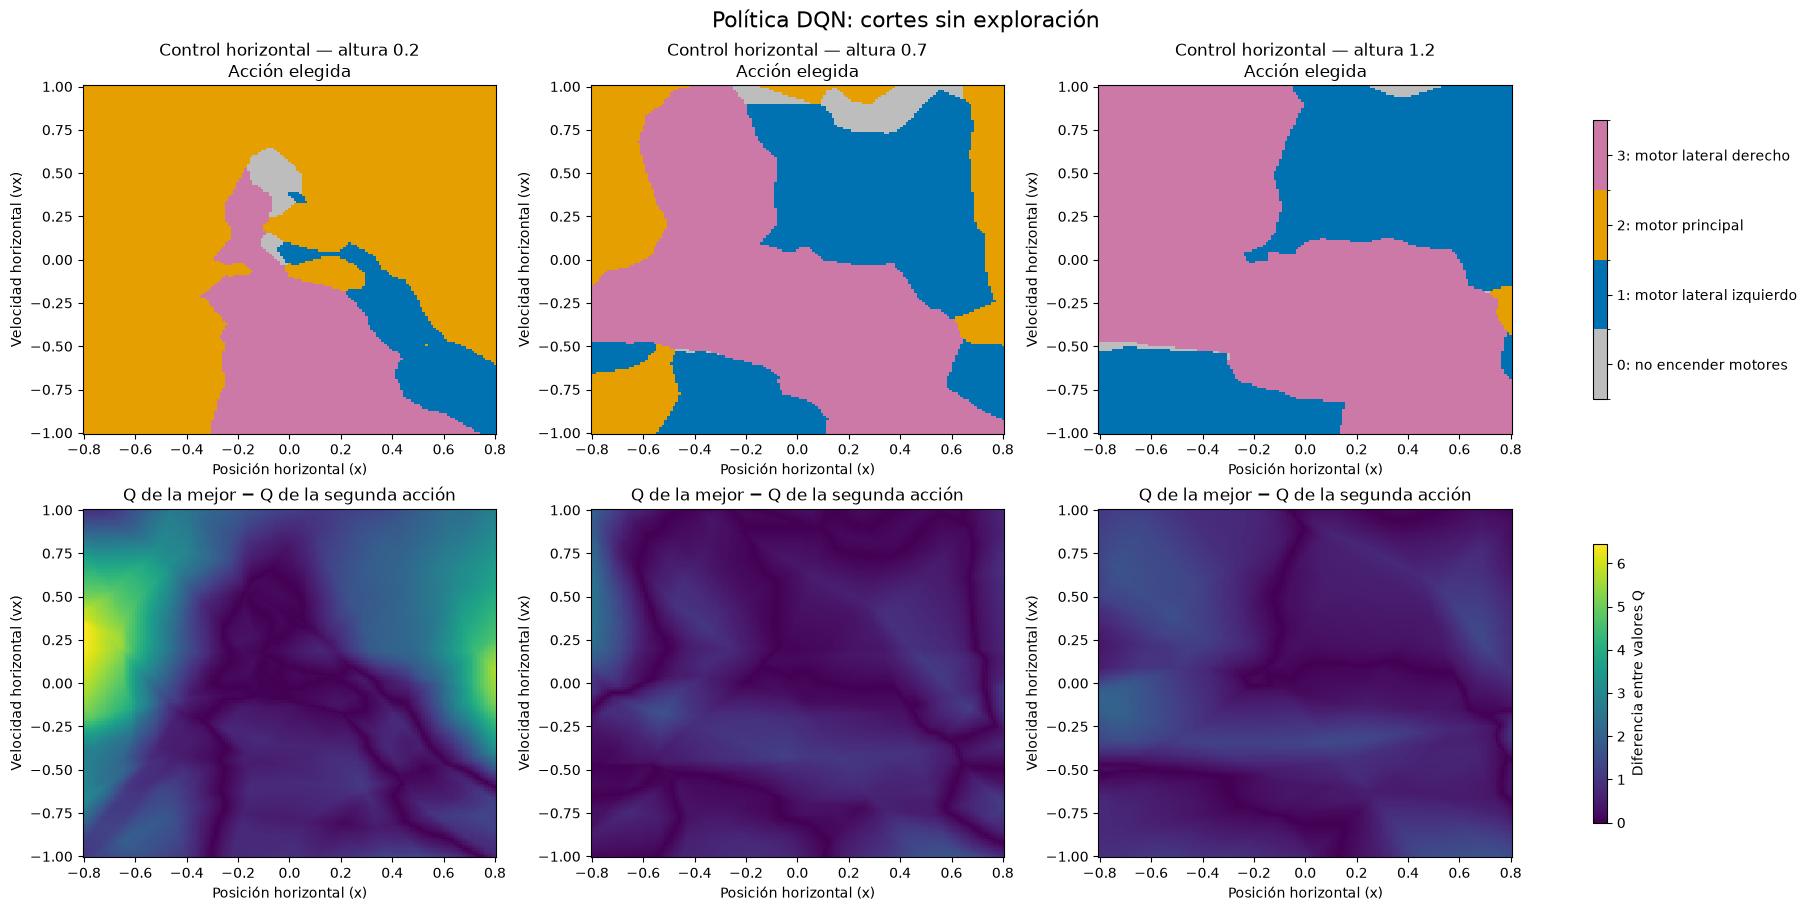

Orientación — altura 0.2 — variables fijas: x=0, y=0.2, vx=0, vy=-0.3, c_izq=0, c_der=0
Orientación — altura 0.7 — variables fijas: x=0, y=0.7, vx=0, vy=-0.3, c_izq=0, c_der=0
Orientación — altura 1.2 — variables fijas: x=0, y=1.2, vx=0, vy=-0.3, c_izq=0, c_der=0


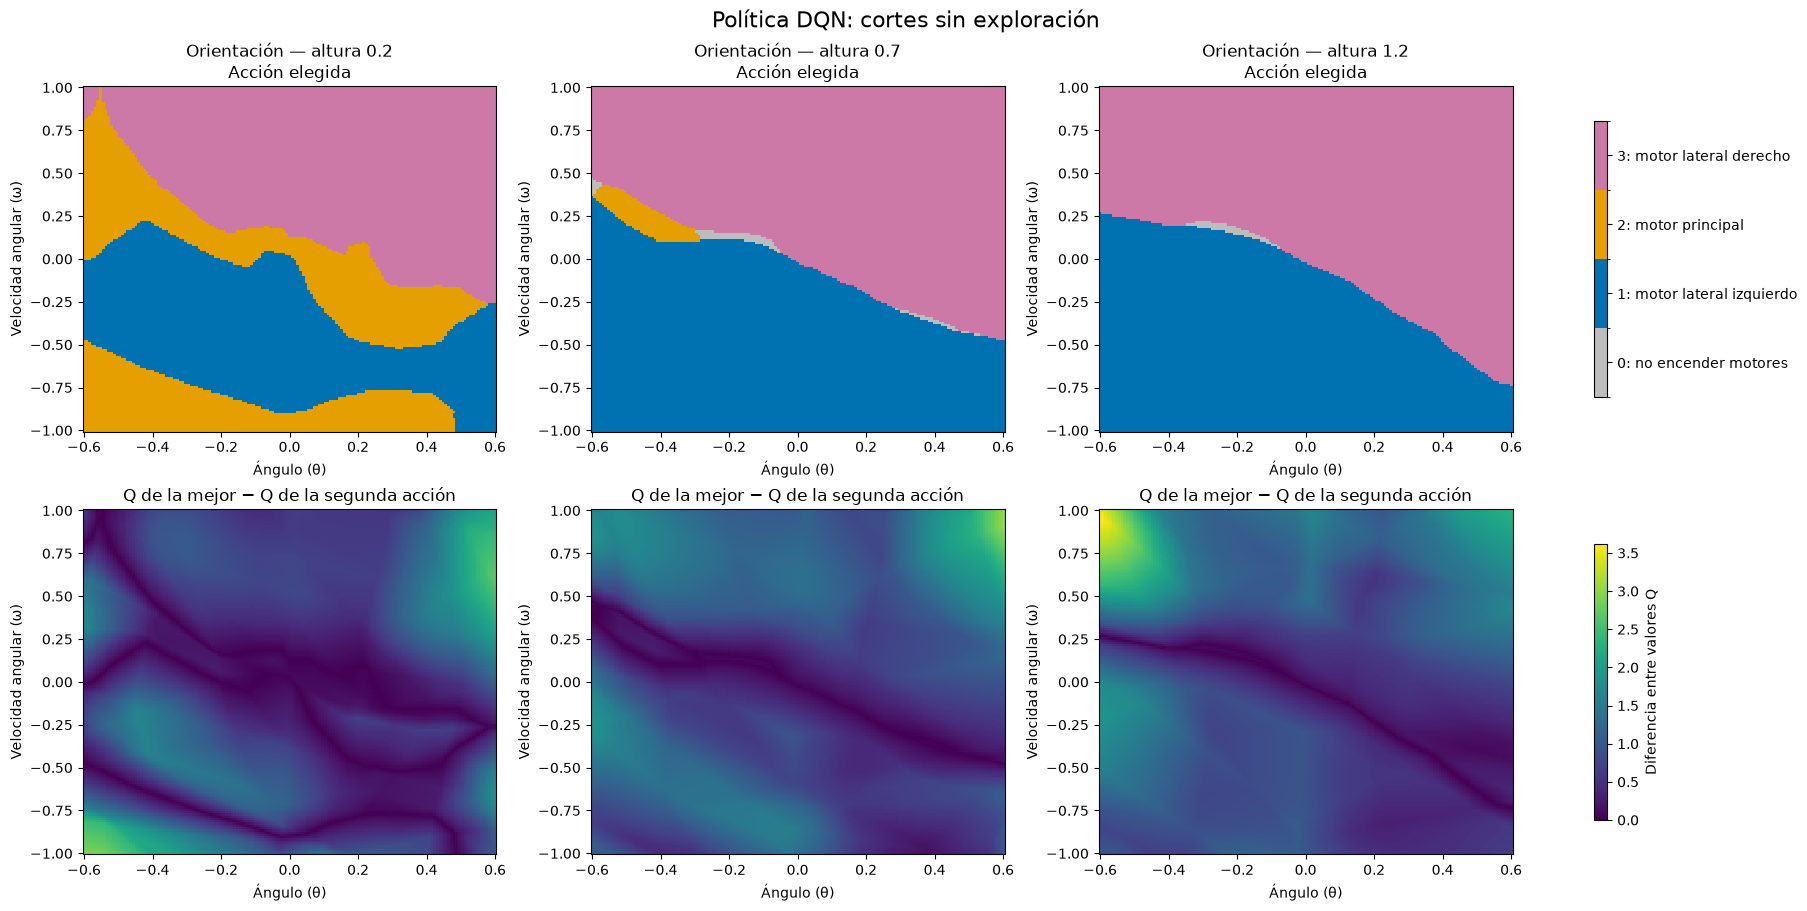

In [16]:
# Comparar la política a distintas alturas.
# Requiere ejecutar antes la celda que define analizar_cortes_politica.

alturas = [0.2, 0.7, 1.2]

# 1. CONTROL HORIZONTAL
# Variamos x y vx.
# Fijamos vy=-0.3, ángulo=0, velocidad angular=0 y contactos=0.
cortes_horizontal = [
    {
        "titulo": f"Control horizontal — altura {altura:g}",
        "indices": (0, 2),
        "rangos": ((-0.8, 0.8), (-1.0, 1.0)),
        "etiquetas": (
            "Posición horizontal (x)",
            "Velocidad horizontal (vx)",
        ),
        "base": [0, altura, 0, -0.3, 0, 0, 0, 0],
    }
    for altura in alturas
]

resultados_horizontal = analizar_cortes_politica(
    agente_dqn, cortes_horizontal
)

# 2. CONTROL DE LA ORIENTACIÓN
# Variamos ángulo y velocidad angular.
# Fijamos x=0, vx=0, vy=-0.3 y contactos=0.
cortes_orientacion = [
    {
        "titulo": f"Orientación — altura {altura:g}",
        "indices": (4, 5),
        "rangos": ((-0.6, 0.6), (-1.0, 1.0)),
        "etiquetas": (
            "Ángulo (θ)",
            "Velocidad angular (ω)",
        ),
        "base": [0, altura, 0, -0.3, 0, 0, 0, 0],
    }
    for altura in alturas
]

resultados_orientacion = analizar_cortes_politica(
    agente_dqn, cortes_orientacion
)

## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


In [17]:
# TODO 3: estudio de ablación
import json
from pathlib import Path

from scipy import stats

EPISODIOS_ABLACION = 900                  # menos que los 1200 del entrenamiento principal, para acotar el cómputo
SEMILLAS_ENTRENAMIENTO = [0, 1, 2, 3, 4]
EPISODIOS_EVALUACION = 100
SEMILLA_EVALUACION = 10_000               # mismos escenarios de evaluación para todas las corridas
ARCHIVO_ABLACION = Path('resultados_ablacion.json')

# Cada variante desactiva un único componente; el resto queda igual al DQN completo.
variantes = {
    "DQN completo": {},
    "Sin target network": {"usar_target_net": False},
    "Sin replay buffer": {"usar_replay_buffer": False},
    "Pérdida MSE (sin Huber)": {"usar_huber": False},
}


def entrenar_y_evaluar(config, semilla):
    """Entrena un DQN desde cero con la semilla dada y lo evalúa sin exploración."""
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla, **config)
    entrenar_agente(agente, env, num_episodios=EPISODIOS_ABLACION, semilla=semilla, verbose=False)
    resultados = evaluar_agente(agente, env, num_episodios=EPISODIOS_EVALUACION,
                                semilla=SEMILLA_EVALUACION)
    env.close()
    return {'recompensa_promedio': resultados['recompensa_promedio'],
            'tasa_exito': resultados['tasa_exito']}


def correr_estudio(configuraciones, archivo, semillas=SEMILLAS_ENTRENAMIENTO):
    """Entrena y evalúa cada configuración con cada semilla. Los resultados se guardan
    en disco a medida que terminan, para poder retomar o re-analizar sin reentrenar.
    Si se cambia algún parámetro del estudio, borrar el archivo."""
    resultados = json.loads(archivo.read_text()) if archivo.exists() else {}

    for nombre, config in configuraciones.items():
        corridas = resultados.setdefault(nombre, {})
        for semilla in semillas:
            if str(semilla) in corridas:
                continue
            print(f"\n{nombre} | semilla {semilla}")
            corridas[str(semilla)] = entrenar_y_evaluar(config, semilla)
            archivo.write_text(json.dumps(resultados, indent=1))
    return resultados


resultados_ablacion = correr_estudio(variantes, ARCHIVO_ABLACION)



DQN completo | semilla 3
Tiempo total de entrenamiento: 558s

DQN completo | semilla 4
Tiempo total de entrenamiento: 560s

Sin target network | semilla 0
Tiempo total de entrenamiento: 489s

Sin target network | semilla 1
Tiempo total de entrenamiento: 349s

Sin target network | semilla 2
Tiempo total de entrenamiento: 366s

Sin target network | semilla 3
Tiempo total de entrenamiento: 68s

Sin target network | semilla 4
Tiempo total de entrenamiento: 368s

Sin replay buffer | semilla 0
Tiempo total de entrenamiento: 319s

Sin replay buffer | semilla 1
Tiempo total de entrenamiento: 303s

Sin replay buffer | semilla 2
Tiempo total de entrenamiento: 274s

Sin replay buffer | semilla 3
Tiempo total de entrenamiento: 279s

Sin replay buffer | semilla 4
Tiempo total de entrenamiento: 232s

Pérdida MSE (sin Huber) | semilla 0
Tiempo total de entrenamiento: 473s

Pérdida MSE (sin Huber) | semilla 1
Tiempo total de entrenamiento: 478s

Pérdida MSE (sin Huber) | semilla 2
Tiempo total de ent

In [18]:
# Recompensa de evaluación por semilla y test estadístico contra el DQN completo
def por_semilla(nombre, campo='recompensa_promedio'):
    return np.array([resultados_ablacion[nombre][str(s)][campo] for s in SEMILLAS_ENTRENAMIENTO])

completo = por_semilla("DQN completo")
num_comparaciones = len(variantes) - 1

print(f"{'Variante':<25}" + "".join(f"{'sem ' + str(s):>9}" for s in SEMILLAS_ENTRENAMIENTO)
      + f"{'media':>9}{'éxito':>8}{'U':>7}{'p':>8}{'p corr.':>9}")

for nombre in variantes:
    recompensas = por_semilla(nombre)
    fila = (f"{nombre:<25}" + "".join(f"{r:9.1f}" for r in recompensas)
            + f"{recompensas.mean():9.1f}{por_semilla(nombre, 'tasa_exito').mean():8.1%}")

    if nombre != "DQN completo":
        # Mann-Whitney U: con 5 semillas por grupo no se puede asumir normalidad.
        # Bonferroni corrige por comparar cada variante contra el mismo DQN completo.
        u, p = stats.mannwhitneyu(recompensas, completo, alternative='two-sided')
        fila += f"{u:7.1f}{p:8.4f}{min(1.0, p * num_comparaciones):9.4f}"
    print(fila)

print(f"\n{len(SEMILLAS_ENTRENAMIENTO)} semillas de entrenamiento, {EPISODIOS_ABLACION} episodios, "
      f"evaluación sobre {EPISODIOS_EVALUACION} episodios sin exploración (recompensa promedio por semilla).")


Variante                     sem 0    sem 1    sem 2    sem 3    sem 4    media   éxito      U       p  p corr.
DQN completo                 182.9    205.1    234.6    251.2    241.7    223.1   70.4%
Sin target network           210.4     -9.8    -26.3   -563.0    236.7    -30.4   30.0%    5.0  0.1508   0.4524
Sin replay buffer            -81.9   -169.6    -39.9    -17.8    -93.2    -80.5    1.0%    0.0  0.0079   0.0238
Pérdida MSE (sin Huber)      268.5    233.7    260.1    259.6    232.8    250.9   90.0%   19.0  0.2222   0.6667

5 semillas de entrenamiento, 900 episodios, evaluación sobre 100 episodios sin exploración (recompensa promedio por semilla).


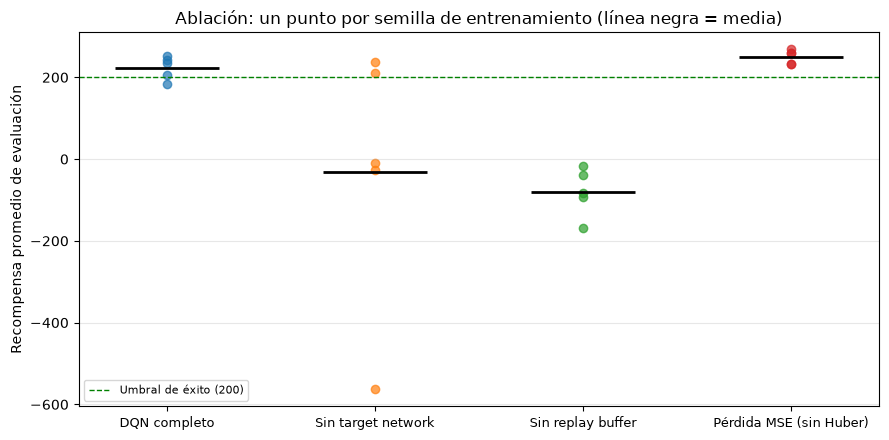

In [19]:
# Recompensa de evaluación por semilla de cada variante
fig, ax = plt.subplots(figsize=(9, 4.5))

for posicion, nombre in enumerate(variantes):
    recompensas = por_semilla(nombre)
    ax.scatter([posicion] * len(recompensas), recompensas, alpha=0.7, label=None)
    ax.hlines(recompensas.mean(), posicion - 0.25, posicion + 0.25, color='black', linewidth=2)

ax.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
ax.set_xticks(range(len(variantes)))
ax.set_xticklabels(variantes, fontsize=9)
ax.set_ylabel("Recompensa promedio de evaluación")
ax.set_title("Ablación: un punto por semilla de entrenamiento (línea negra = media)")
ax.legend(fontsize=8)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### Cómo leer los resultados de la ablación

* **Tabla.** Cada fila es una variante y cada columna una semilla de entrenamiento: el valor es la
  recompensa promedio de evaluación de esa corrida. `éxito` es la tasa de éxito promedio entre semillas.
* **U y p.** El test compara las 5 recompensas de la variante contra las 5 del DQN completo. `p` chico
  indica que es poco probable que ambos grupos vengan de la misma distribución. `p corr.` es el `p`
  multiplicado por 3 (Bonferroni) y es el que se compara con 0.05.
* **Sin significancia no es "sin efecto".** Con 5 semillas el test tiene poca potencia: si una variante es
  muy variable entre semillas, puede ser peor en promedio y aun así no dar significativo.
* **Dirección.** El test es bilateral, así que `p` chico también puede significar que la variante es
  *mejor* que el completo. Hay que mirar el signo de la diferencia de medias.

La celda siguiente resume cada variante con la diferencia de medias, la dispersión entre semillas y la
probabilidad de superioridad.


In [20]:
# Resumen por variante: tamaño y dirección del efecto, no solo el p-valor
ALFA = 0.05

print(f"{'Variante':<25}{'media':>8}{'desv.':>8}{'mediana':>9}{'peor':>8}{'mejor':>8}"
      f"{'R≥200':>7}{'Δ media':>9}{'P(sup.)':>9}   veredicto")

for nombre in variantes:
    recompensas = por_semilla(nombre)
    fila = (f"{nombre:<25}{recompensas.mean():8.1f}{recompensas.std(ddof=1):8.1f}"
            f"{np.median(recompensas):9.1f}{recompensas.min():8.1f}{recompensas.max():8.1f}"
            f"{(recompensas >= UMBRAL_EXITO).sum():>5}/{len(recompensas)}")

    if nombre == "DQN completo":
        print(fila)
        continue

    u, p = stats.mannwhitneyu(recompensas, completo, alternative='two-sided')
    p_corregido = min(1.0, p * num_comparaciones)
    diferencia = recompensas.mean() - completo.mean()
    # Probabilidad de superioridad: chance de que una corrida de la variante supere a una del completo
    prob_superioridad = u / (len(recompensas) * len(completo))

    if p_corregido >= ALFA:
        veredicto = "sin diferencia significativa"
    else:
        veredicto = "significativamente peor" if diferencia < 0 else "significativamente mejor"
    print(f"{fila}{diferencia:9.1f}{prob_superioridad:9.2f}   {veredicto}")

print(f"\nΔ media = media de la variante − media del DQN completo. P(sup.) = 0.5 significa solapamiento total; "
      f"0 o 1, grupos sin solapar.\nVeredicto con p corregido (Bonferroni) y α = {ALFA}.")


Variante                    media   desv.  mediana    peor   mejor  R≥200  Δ media  P(sup.)   veredicto
DQN completo                223.1    28.3    234.6   182.9   251.2    4/5
Sin target network          -30.4   321.5     -9.8  -563.0   236.7    2/5   -253.5     0.20   sin diferencia significativa
Sin replay buffer           -80.5    58.5    -81.9  -169.6   -17.8    0/5   -303.6     0.00   significativamente peor
Pérdida MSE (sin Huber)     250.9    16.5    259.6   232.8   268.5    5/5     27.8     0.76   sin diferencia significativa

Δ media = media de la variante − media del DQN completo. P(sup.) = 0.5 significa solapamiento total; 0 o 1, grupos sin solapar.
Veredicto con p corregido (Bonferroni) y α = 0.05.


### Qué mide el test de Mann-Whitney

Se ordenan las 10 recompensas (5 de la variante y 5 del DQN completo) y se mira en qué posiciones
quedaron las de la variante. **U** cuenta, sobre todos los pares (corrida de la variante, corrida del
completo), en cuántos gana la variante: va de 0 (la variante pierde siempre) a 25 (gana siempre) y
**U = 12.5** es el solapamiento total.

La hipótesis nula dice que las dos configuraciones son iguales, de modo que cualquier reparto de las 10 corridas
en dos grupos de 5 sería igual de probable. Hay 252 repartos posibles; el gráfico muestra la distribución de U
sobre todos ellos. El **p-valor** es la probabilidad, bajo esa hipótesis, de obtener un U al menos tan alejado de
12.5 como el observado: es la fracción de barras rojas.


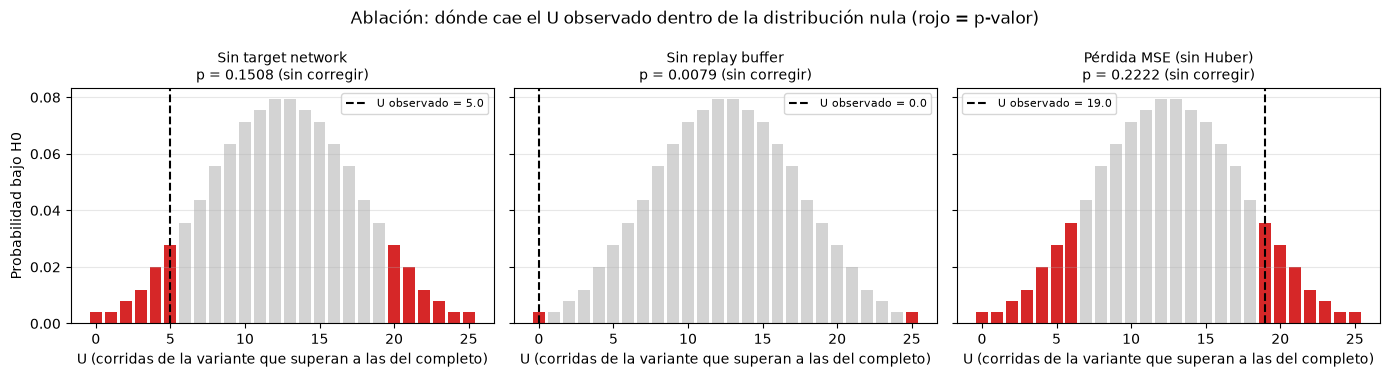

In [21]:
# Distribución exacta de U bajo la hipótesis nula, con el U observado de cada variante
from itertools import combinations

n = len(completo)
# Todas las formas de repartir los rangos 1..10 entre los dos grupos (sin empates)
u_nulo = np.array([sum(rangos) - n * (n + 1) / 2 for rangos in combinations(range(1, 2 * n + 1), n)])
valores, frecuencias = np.unique(u_nulo, return_counts=True)

fig, ejes = plt.subplots(1, num_comparaciones, figsize=(14, 3.8), sharey=True)

for eje, nombre in zip(ejes, list(variantes)[1:]):
    u, p = stats.mannwhitneyu(por_semilla(nombre), completo, alternative='two-sided')
    # Reparticiones tan o más extremas que la observada (a cualquiera de los dos lados)
    extremos = np.abs(valores - n * n / 2) >= abs(u - n * n / 2)

    eje.bar(valores, frecuencias / len(u_nulo), color=np.where(extremos, 'tab:red', 'lightgray'))
    eje.axvline(u, color='black', linestyle='--', label=f"U observado = {u:.1f}")
    eje.set_title(f"{nombre}\np = {p:.4f} (sin corregir)", fontsize=10)
    eje.set_xlabel("U (corridas de la variante que superan a las del completo)")
    eje.legend(fontsize=8)
    eje.grid(True, axis='y', alpha=0.3)

ejes[0].set_ylabel("Probabilidad bajo H0")
fig.suptitle("Ablación: dónde cae el U observado dentro de la distribución nula (rojo = p-valor)")
plt.tight_layout()
plt.show()


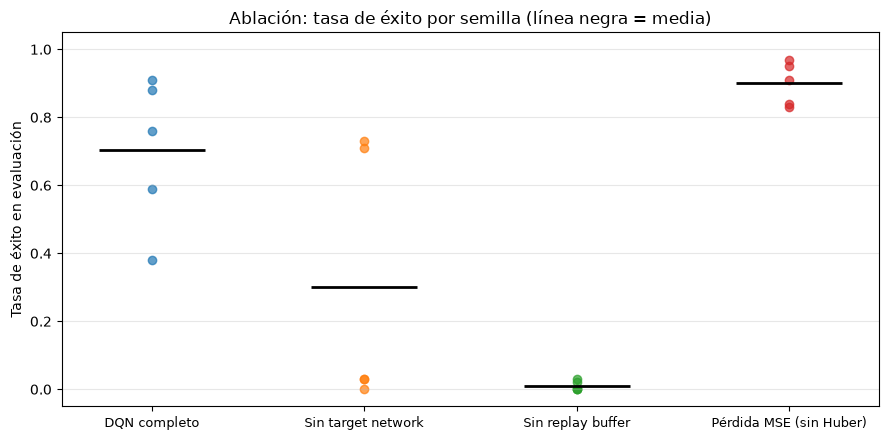

In [22]:
# Tasa de éxito (R ≥ 200) de evaluación por semilla de cada variante
fig, ax = plt.subplots(figsize=(9, 4.5))

for posicion, nombre in enumerate(variantes):
    tasas = por_semilla(nombre, 'tasa_exito')
    ax.scatter([posicion] * len(tasas), tasas, alpha=0.7)
    ax.hlines(tasas.mean(), posicion - 0.25, posicion + 0.25, color='black', linewidth=2)

ax.set_xticks(range(len(variantes)))
ax.set_xticklabels(variantes, fontsize=9)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito en evaluación")
ax.set_title("Ablación: tasa de éxito por semilla (línea negra = media)")
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### Efecto de la arquitectura de la red

La ablación quita componentes del algoritmo; esta prueba varía en cambio la **capacidad de la red**: el número de
capas ocultas (1, 2, 3) y el ancho de cada una (32, 64, 128, 256), con todo lo demás igual al DQN completo. La
configuración usada hasta ahora es `2x64`. Se usan menos semillas que en la ablación para acotar el cómputo.


In [23]:
# Entrenar y evaluar cada combinación de capas y ancho
CAPAS = [1, 2, 3]
ANCHOS = [32, 64, 128, 256]
SEMILLAS_ARQUITECTURA = SEMILLAS_ENTRENAMIENTO[:3]
ARCHIVO_ARQUITECTURA = Path('resultados_arquitectura.json')

arquitecturas = {f"{capas}x{ancho}": {"capas_ocultas": (ancho,) * capas}
                 for capas in CAPAS for ancho in ANCHOS}

resultados_arquitectura = correr_estudio(arquitecturas, ARCHIVO_ARQUITECTURA, SEMILLAS_ARQUITECTURA)



1x32 | semilla 0
Tiempo total de entrenamiento: 482s

1x32 | semilla 1
Tiempo total de entrenamiento: 481s

1x32 | semilla 2
Tiempo total de entrenamiento: 510s

1x64 | semilla 0
Tiempo total de entrenamiento: 670s

1x64 | semilla 1
Tiempo total de entrenamiento: 902s

1x64 | semilla 2
Tiempo total de entrenamiento: 871s

1x128 | semilla 0
Tiempo total de entrenamiento: 942s

1x128 | semilla 1
Tiempo total de entrenamiento: 790s

1x128 | semilla 2
Tiempo total de entrenamiento: 963s

1x256 | semilla 0
Tiempo total de entrenamiento: 708s

1x256 | semilla 1
Tiempo total de entrenamiento: 639s

1x256 | semilla 2
Tiempo total de entrenamiento: 700s

2x32 | semilla 0
Tiempo total de entrenamiento: 707s

2x32 | semilla 1
Tiempo total de entrenamiento: 768s

2x32 | semilla 2
Tiempo total de entrenamiento: 747s

2x64 | semilla 0
Tiempo total de entrenamiento: 754s

2x64 | semilla 1
Tiempo total de entrenamiento: 648s

2x64 | semilla 2
Tiempo total de entrenamiento: 704s

2x128 | semilla 0
Tie

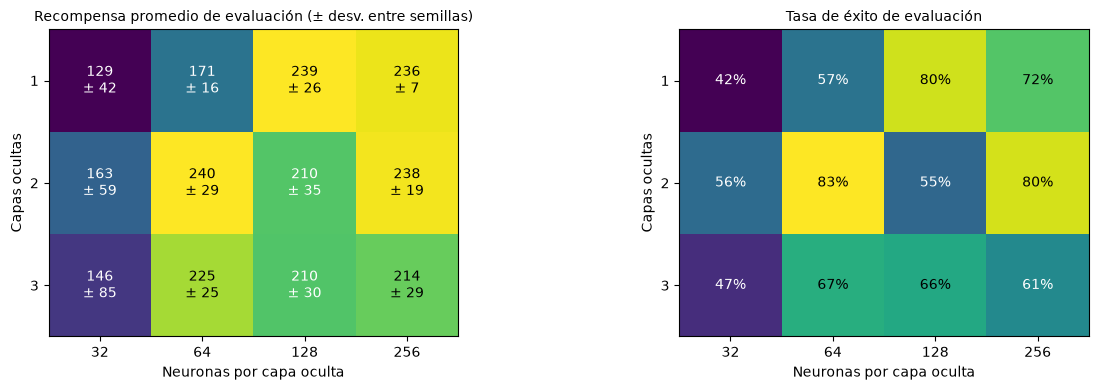

In [24]:
# Resultados por arquitectura: filas = capas ocultas, columnas = ancho de cada capa
def por_arquitectura(campo, estadistico):
    return np.array([[estadistico([resultados_arquitectura[f"{capas}x{ancho}"][str(s)][campo]
                                   for s in SEMILLAS_ARQUITECTURA])
                      for ancho in ANCHOS] for capas in CAPAS])

recompensa_media = por_arquitectura('recompensa_promedio', np.mean)
recompensa_desv = por_arquitectura('recompensa_promedio', np.std)
tasa_exito = por_arquitectura('tasa_exito', np.mean)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
paneles = [
    (ejes[0], recompensa_media, "Recompensa promedio de evaluación (± desv. entre semillas)",
     [[f"{m:.0f}\n± {d:.0f}" for m, d in zip(fm, fd)] for fm, fd in zip(recompensa_media, recompensa_desv)]),
    (ejes[1], tasa_exito, "Tasa de éxito de evaluación",
     [[f"{t:.0%}" for t in fila] for fila in tasa_exito]),
]

for eje, valores, titulo, textos in paneles:
    eje.imshow(valores, cmap='viridis')
    for i in range(len(CAPAS)):
        for j in range(len(ANCHOS)):
            eje.text(j, i, textos[i][j], ha='center', va='center',
                     color='white' if valores[i, j] < np.median(valores) else 'black')
    eje.set_xticks(range(len(ANCHOS)))
    eje.set_xticklabels(ANCHOS)
    eje.set_yticks(range(len(CAPAS)))
    eje.set_yticklabels(CAPAS)
    eje.set_xlabel("Neuronas por capa oculta")
    eje.set_ylabel("Capas ocultas")
    eje.set_title(titulo, fontsize=10)

plt.tight_layout()
plt.show()
